# Project 2 Checkpoint: Education
**Working proposition:** By 2019, access to secondary education was close to universal.

Open in Google Colab, select **Runtime → Run all**, and upload your **education.csv** when prompted. Four charts will appear below. An optional last cell downloads them as a ZIP.

All charts concern adolescents of lower-secondary-school age. Being enrolled does not establish attendance, completion, learning quality, or enrollment specifically at the secondary level. The proposition is intentionally debatable.

In [ ]:
import io
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

try:
    from google.colab import files
    uploaded = files.upload()
    if not uploaded:
        raise ValueError("Please upload education.csv, then rerun this cell.")
    filename = next(iter(uploaded))
    df = pd.read_csv(io.BytesIO(uploaded[filename]))
except ImportError:
    df = pd.read_csv("education.csv")

column = "average_value_Adolescents out of school (% of lower secondary school age)"
required = {"Country Name", "Year", column}
if not required.issubset(df.columns):
    raise ValueError("Upload the cleaned education.csv from the course dataset.")
df = df.rename(columns={column: "out_of_school"})
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
df["out_of_school"] = pd.to_numeric(df["out_of_school"], errors="coerce")
df["in_school"] = 100 - df["out_of_school"]
world = df.loc[df["Country Name"].eq("World") & df["Year"].between(1998, 2019)].sort_values("Year")
world_2019 = world.loc[world["Year"].eq(2019)].iloc[0]
output = Path("education_charts")
output.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 5), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

def finish(fig, ax, filename, maximum=100):
    ax.set_ylim(0, maximum)
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.grid(axis="y", alpha=.2)
    ax.set_axisbelow(True)
    fig.text(.02, .01, "Source: World Bank education.csv | Lower-secondary-school-age adolescents", fontsize=8)
    fig.tight_layout(rect=[0,.05,1,1])
    fig.savefig(output / filename, dpi=200, bbox_inches="tight")
    plt.show()

print("Data loaded. Ready to draw four charts.")

Saving education.csv to education.csv
Data loaded. Ready to draw four charts.


## 1. Supporting: Global participation over time
A line chart emphasizes improvement. The plotted share is 100 minus the out-of-school rate.

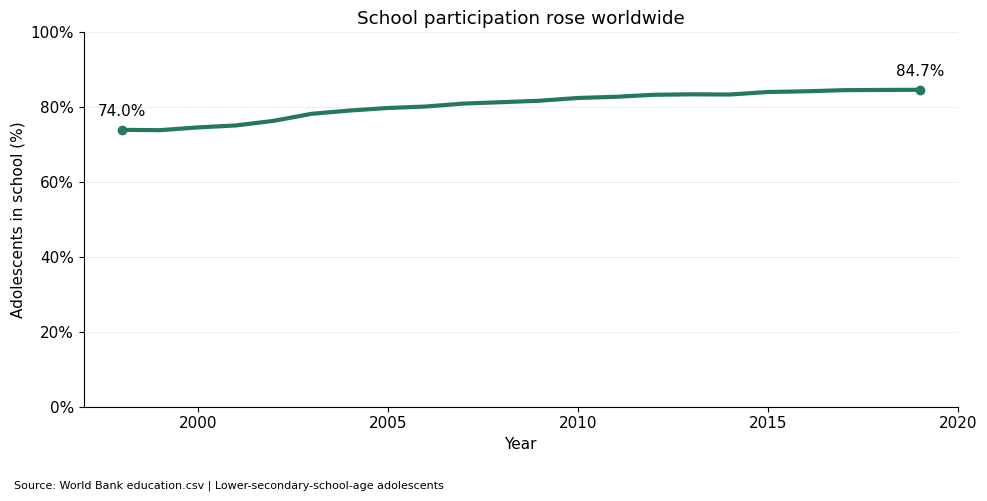

In [ ]:
fig, ax = plt.subplots()
ax.plot(world["Year"], world["in_school"], color="#247A57", linewidth=3)
valid = world.dropna(subset=["in_school"])
for _, row in valid.iloc[[0, -1]].iterrows():
    ax.scatter(row["Year"], row["in_school"], color="#247A57")
    ax.annotate(f'{row["in_school"]:.1f}%', (row["Year"], row["in_school"]),
                xytext=(0,10), textcoords="offset points", ha="center")
ax.set(title="School participation rose worldwide", xlabel="Year", ylabel="Adolescents in school (%)", xlim=(1997,2020))
finish(fig, ax, "01_global_participation.png")

## 2. Supporting: Participation in 2019
A 100% stacked bar emphasizes the large share enrolled worldwide. It also shows the excluded share.

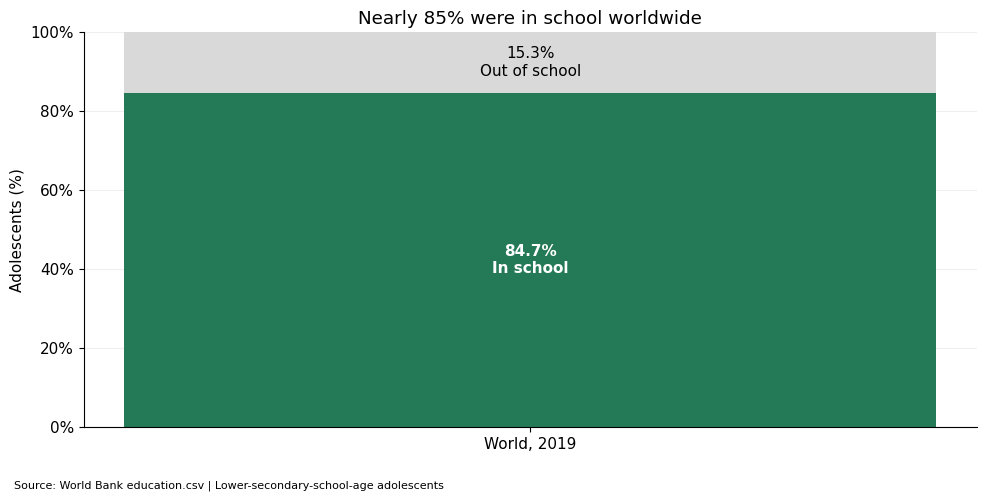

In [ ]:
inside, outside = world_2019["in_school"], world_2019["out_of_school"]
fig, ax = plt.subplots()
ax.bar(["World, 2019"], [inside], color="#247A57", width=.5)
ax.bar(["World, 2019"], [outside], bottom=[inside], color="#D9D9D9", width=.5)
ax.text(0, inside/2, f"{inside:.1f}%\nIn school", ha="center", va="center", color="white", weight="bold")
ax.text(0, inside+outside/2, f"{outside:.1f}%\nOut of school", ha="center", va="center")
ax.set(title="Nearly 85% were in school worldwide", ylabel="Adolescents (%)")
finish(fig, ax, "02_participation_2019.png")

## 3. Opposing: Income-group comparison
A bar chart reveals inequality hidden by the global average. World overlaps with the income groups; these are not additive categories.

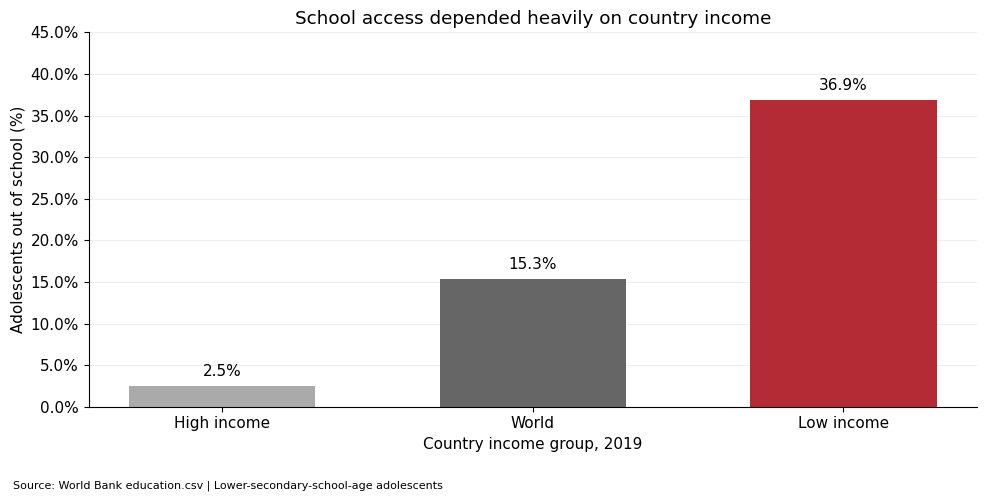

In [ ]:
groups = ["High income", "World", "Low income"]
comparison = df.loc[df["Year"].eq(2019) & df["Country Name"].isin(groups)].set_index("Country Name").reindex(groups)
fig, ax = plt.subplots()
bars = ax.bar(groups, comparison["out_of_school"], color=["#AAAAAA", "#666666", "#B52B35"], width=.6)
ax.bar_label(bars, fmt="%.1f%%", padding=5)
ax.set(title="School access depended heavily on country income", ylabel="Adolescents out of school (%)", xlabel="Country income group, 2019")
finish(fig, ax, "03_income_group_comparison.png", maximum=45)

## 4. Opposing: Income-group trends
Two lines show a persistent gap while acknowledging improvement. Missing years are retained as gaps rather than connected across.

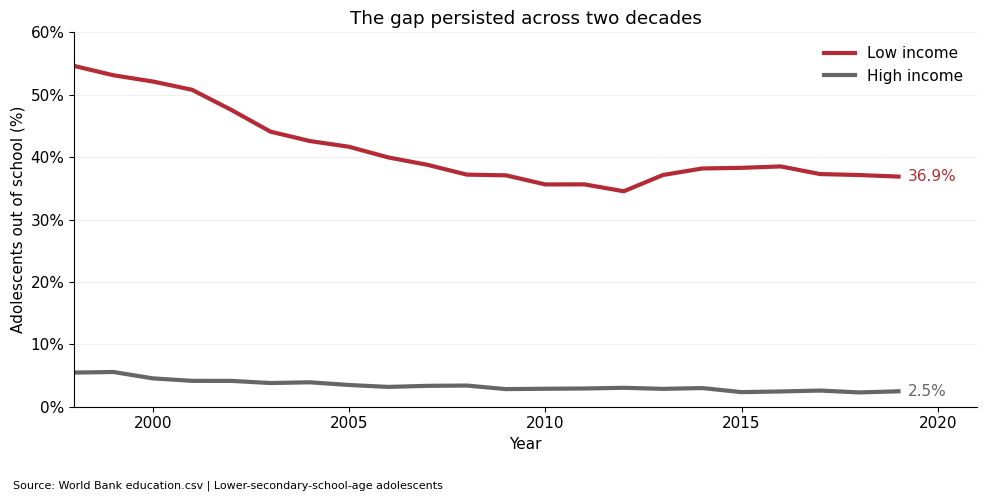

In [ ]:
fig, ax = plt.subplots()
for group, color in [("Low income", "#B52B35"), ("High income", "#666666")]:
    series = df.loc[df["Country Name"].eq(group)].set_index("Year")["out_of_school"].reindex(range(1998,2020))
    ax.plot(series.index, series, label=group, color=color, linewidth=3)
    last = series.dropna()
    ax.annotate(f"{last.iloc[-1]:.1f}%", (last.index[-1],last.iloc[-1]), xytext=(7,0), textcoords="offset points", va="center", color=color)
ax.set(title="The gap persisted across two decades", xlabel="Year", ylabel="Adolescents out of school (%)", xlim=(1998,2021))
ax.legend(frameon=False)
finish(fig, ax, "04_income_group_trends.png", maximum=60)

## Checkpoint write-up notes
- **Proposition:** By 2019, access to secondary education was close to universal.
- Charts 1 and 2 emphasize global improvement and the majority in school. They do not establish universal access.
- Charts 3 and 4 emphasize unequal access by country income group.
- **Persuasive choices:** positive framing, global aggregation, group selection, and different axis ranges. Calling 84.7% “close to universal” is a debatable interpretation.
- **Measurement limitation:** the indicator measures out-of-school status for a particular age group, not secondary completion or education quality.
- **Your preference:** Add which chart approach you are leaning toward and why.

For the checkpoint PDF: place charts 1–2 on page 1, charts 3–4 on page 2, and your write-up on page 3. This notebook produces the charts; it is not itself that PDF.

In [ ]:
# Optional: download all four PNG charts as a ZIP.
import shutil
zip_path = shutil.make_archive("education_charts", "zip", output)
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Saved:", zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>